In [119]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from Flame_Reference_Solution import T_all, N, T_0, G_0, L, ATM, phi, p_in, R, A, NU, EA, W, LAM, CP, QF, rho_0, YF_0, T_ad

# float64 on purpose: u = (c - sqrt(c^2 - 4RT/W))/2 subtracts two nearly equal numbers,
# which loses most of its digits in float32
torch.set_default_dtype(torch.float64)

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# ---------------- Scaling ----------------
a_x = 1.0 / L                      # x_star = a_x * x, so the network sees x_star in [0, 1]
a_T = 5.0 / T_ad                   # only used to size the loss terms
res_scale = a_T / (a_x * rho_0 * CP * 1.0)   # divides the residual by its typical size (~1e9)

In [120]:
class TemperatureNN(nn.Module):
    """Standard feedforward neural network"""
    def __init__(self, hidden_size=64, n_layers=3):
        super().__init__()

        layers = []
        layers.append(nn.Linear(1, hidden_size))  # Input: x_star (scaled position)
        
        # Hidden layers
        for _ in range(n_layers - 1):
            layers.append(nn.Tanh())  # Smooth activation (important!)
            layers.append(nn.Linear(hidden_size, hidden_size))

        layers.append(nn.Tanh())
        layers.append(nn.Linear(hidden_size, 1))  # Output: theta, the dimensionless temperature

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def temperature(model, x):
    """theta = 0 is cold gas, theta = 1 is fully burnt gas.  T = T_0 + (T_ad - T_0) * theta"""
    return T_0 + (T_ad - T_0) * torch.sigmoid(model(x))

In [121]:
def weak_physics_loss(model, x_colloc, sL, n_test=10):

    # x_colloc is normalized position x_star in [0, 1]
    x_star = x_colloc.clone().detach().requires_grad_(True)

    # Convert normalized position to physical position
    x_phys = x_star / a_x

    # Predict temperature
    T = temperature(model, x_star)

    # First derivative with respect to x_star
    # Second derivative calculation isn't necessary!
    dT_dxs = torch.autograd.grad(
        outputs=T,
        inputs=x_star,
        grad_outputs=torch.ones_like(T),
        create_graph=True
    )[0]

    # Convert to physical derivative dT/dx
    dT = dT_dxs * a_x

    # Physical closure relations
    sL_pos = torch.clamp(sL, min=1e-6)

    c = sL_pos + R * T_0 / (W * sL_pos)

    u = 0.5 * (
        c - torch.sqrt(c**2 - 4.0 * R * T / W)
    )

    rho = rho_0 * sL_pos / u

    YF = YF_0 + CP * (T_0 - T) / QF
    YF = torch.clamp(YF, min=0.0)

    omega = A * torch.exp(-EA / (R * T)) * (rho * YF)**NU

    # Construct test functions and their physical derivatives
    phi_list = []
    dphi_list = []

    for j in range(n_test):

        phi_j = x_star * torch.cos(j * torch.pi * x_star)

        dphi_dxs = (
            torch.cos(j * torch.pi * x_star)
            - x_star * j * torch.pi
            * torch.sin(j * torch.pi * x_star)
        )

        dphi_dx = dphi_dxs * a_x

        phi_list.append(phi_j)
        dphi_list.append(dphi_dx)

    phi = torch.cat(phi_list, dim=1)
    dphi = torch.cat(dphi_list, dim=1)

    integrand_advection = rho_0 * sL_pos * CP * dT * phi
    integrand_diffusion = LAM * dT * dphi
    integrand_reaction = QF * omega * phi

    integrand = (
        integrand_advection
        + integrand_diffusion
        - integrand_reaction
    )

    R_weak = torch.trapezoid(
        integrand,
        x_phys.squeeze(),
        dim=0
    )

    loss_weak = torch.mean((R_weak * res_scale)**2)

    return loss_weak

def boundary_loss(model):

    x_bc = torch.zeros(1, 1, requires_grad=True)

    T_bc = temperature(model, x_bc)

    dT_bc = torch.autograd.grad(
        outputs=T_bc,
        inputs=x_bc,
        grad_outputs=torch.ones_like(T_bc),
        create_graph=True
    )[0] * a_x

    loss_T0 = torch.mean(((T_bc - T_0) * a_T)**2)

    loss_G0 = torch.mean(
        ((dT_bc - G_0) * a_T / a_x)**2
    )

    return loss_T0 + loss_G0

In [122]:
model = TemperatureNN(hidden_size=64, n_layers=3)
# Start near the cold inlet state; temperature() maps this logit through sigmoid.
with torch.no_grad():
    model.network[-1].weight.mul_(0.01)
    model.network[-1].bias.fill_(-4.0)

sL_raw = nn.Parameter(torch.tensor(0.0))

# Initialize physical flame speed to 0.4 m/s
with torch.no_grad():
    sL_raw.fill_(torch.log(torch.expm1(torch.tensor(0.4 - 1e-6))).item())

def get_sL():
    return torch.nn.functional.softplus(sL_raw) + 1e-6

print("Raw:", sL_raw.item())
print("Physical flame speed:", get_sL().item())

N_COLLOC = 1000

optimizer = optim.Adam(
    list(model.parameters()) + [sL_raw],
    lr=1e-3
)

num_epochs = 30000


Raw: -0.7096359648367934
Physical flame speed: 0.4


In [123]:
# Initialize physical flame speed to 0.4 m/s
with torch.no_grad():
    sL_raw.fill_(torch.log(torch.expm1(torch.tensor(0.4 - 1e-6))).item())
optimizer = optim.Adam(list(model.parameters()) + [sL_raw], lr=1e-3)
print("Starting sL guess:", get_sL().item(), "m/s")
x_colloc = torch.linspace(0.0, 1.0, N_COLLOC).reshape(-1, 1)

weak_loss_history_uniform = []
bc_loss_history_uniform = []
sl_uniform = []

for epoch in range(num_epochs):

    optimizer.zero_grad()

    # Calculate current positive flame speed
    sL = get_sL()
    sl_uniform.append(get_sL().item())
    
    # Calculate losses
    loss_weak = weak_physics_loss(
        model, x_colloc, sL
    )

    loss_bc = boundary_loss(model)
    weak_loss_history_uniform.append(loss_weak.item())
    bc_loss_history_uniform.append(loss_bc.item())

    # Combine losses
    loss = loss_weak + loss_bc

    # Fail before an invalid loss or gradient can corrupt sL_raw and the network.
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at epoch {epoch}; inspect T and omega in weak_physics_loss.")

    # Backpropagation
    loss.backward()
    params = list(model.parameters()) + [sL_raw]
    if any(p.grad is not None and not torch.isfinite(p.grad).all() for p in params):
        raise FloatingPointError(f"Non-finite gradient at epoch {epoch}; parameters were not updated.")
    torch.nn.utils.clip_grad_norm_(params, max_norm=1.0)

    # Update network parameters AND flame speed

    optimizer.step()
    
    if epoch % 2000 == 0:
        print(
            f"Epoch {epoch}: "
            f"Loss = {loss.item():.6e}, "
            f"sL = {get_sL().item():.6f} m/s"
        )

if "pinn_profiles" not in globals():
    pinn_profiles = {}

with torch.no_grad():
    x_plot = torch.linspace(0.0, 1.0, 500).reshape(-1, 1)
    pinn_profiles["Uniform"] = {
        "x_mm": (x_plot.squeeze() / a_x * 1e3).cpu().numpy(),
        "T": temperature(model, x_plot).squeeze().cpu().numpy(),
        "sL": get_sL().item(),
    }

Starting sL guess: 0.4 m/s
Epoch 0: Loss = 2.612355e-02, sL = 0.400000 m/s
Epoch 2000: Loss = 1.475232e-05, sL = 1.439856 m/s
Epoch 4000: Loss = 8.911873e-06, sL = 0.849676 m/s
Epoch 6000: Loss = 3.013015e-05, sL = 0.515973 m/s
Epoch 8000: Loss = 6.808169e-06, sL = 0.367667 m/s
Epoch 10000: Loss = 6.673575e-06, sL = 0.299577 m/s
Epoch 12000: Loss = 8.315001e-06, sL = 0.297554 m/s
Epoch 14000: Loss = 8.924818e-06, sL = 0.689981 m/s
Epoch 16000: Loss = 6.337224e-06, sL = 0.647044 m/s
Epoch 18000: Loss = 2.210239e-05, sL = 0.365897 m/s
Epoch 20000: Loss = 1.886103e-05, sL = 0.246617 m/s
Epoch 22000: Loss = 4.696337e-06, sL = 0.191174 m/s
Epoch 24000: Loss = 5.552453e-06, sL = 0.193631 m/s
Epoch 26000: Loss = 4.866782e-06, sL = 0.301795 m/s
Epoch 28000: Loss = 5.760296e-06, sL = 0.345417 m/s


In [124]:
# Initialize physical flame speed to 0.4 m/s
with torch.no_grad():
    sL_raw.fill_(torch.log(torch.expm1(torch.tensor(0.4 - 1e-6))).item())
optimizer = optim.Adam(list(model.parameters()) + [sL_raw], lr=1e-3)
print("Starting sL guess:", get_sL().item(), "m/s")
x_uniform = torch.linspace(0.0, 1.0, N_COLLOC).reshape(-1, 1)
x_colloc = x_uniform**2
weak_loss_history_cluster = []
bc_loss_history_cluster = []
sl_cluster = []


for epoch in range(num_epochs):

    optimizer.zero_grad()

    # Calculate current positive flame speed
    sL = get_sL()
    sl_cluster.append(get_sL().item())

    # Calculate losses
    loss_weak = weak_physics_loss(
        model, x_colloc, sL
    )

    loss_bc = boundary_loss(model)
    weak_loss_history_cluster.append(loss_weak.item())
    bc_loss_history_cluster.append(loss_bc.item())

    # Combine losses
    loss = loss_weak + loss_bc

    # Fail before an invalid loss or gradient can corrupt sL_raw and the network.
    if not torch.isfinite(loss):
        raise FloatingPointError(f"Non-finite loss at epoch {epoch}; inspect T and omega in weak_physics_loss.")

    # Backpropagation
    loss.backward()
    params = list(model.parameters()) + [sL_raw]
    if any(p.grad is not None and not torch.isfinite(p.grad).all() for p in params):
        raise FloatingPointError(f"Non-finite gradient at epoch {epoch}; parameters were not updated.")
    torch.nn.utils.clip_grad_norm_(params, max_norm=1.0)

    # Update network parameters AND flame speed

    optimizer.step()
    
    if epoch % 2000 == 0:
        print(
            f"Epoch {epoch}: "
            f"Loss = {loss.item():.6e}, "
            f"sL = {get_sL().item():.6f} m/s"
        )


if "pinn_profiles" not in globals():
    pinn_profiles = {}

with torch.no_grad():
    x_plot = torch.linspace(0.0, 1.0, 500).reshape(-1, 1)
    pinn_profiles["Clustered near inlet"] = {
        "x_mm": (x_plot.squeeze() / a_x * 1e3).cpu().numpy(),
        "T": temperature(model, x_plot).squeeze().cpu().numpy(),
        "sL": get_sL().item(),
    }

Starting sL guess: 0.4 m/s
Epoch 0: Loss = 5.628284e-06, sL = 0.399764 m/s
Epoch 2000: Loss = 3.652597e-06, sL = 0.186498 m/s
Epoch 4000: Loss = 4.829746e-06, sL = 0.200378 m/s
Epoch 6000: Loss = 3.474989e-06, sL = 0.205588 m/s
Epoch 8000: Loss = 5.486485e-06, sL = 0.212900 m/s
Epoch 10000: Loss = 2.989746e-06, sL = 0.215087 m/s
Epoch 12000: Loss = 4.695898e-06, sL = 0.229790 m/s
Epoch 14000: Loss = 3.651565e-06, sL = 0.214219 m/s
Epoch 16000: Loss = 3.943299e-06, sL = 0.275885 m/s
Epoch 18000: Loss = 5.332662e-06, sL = 0.274954 m/s
Epoch 20000: Loss = 3.484786e-06, sL = 0.242184 m/s
Epoch 22000: Loss = 2.706009e-06, sL = 0.256595 m/s
Epoch 24000: Loss = 4.440498e-06, sL = 0.280158 m/s
Epoch 26000: Loss = 2.310988e-06, sL = 0.197349 m/s
Epoch 28000: Loss = 3.949928e-06, sL = 0.216090 m/s


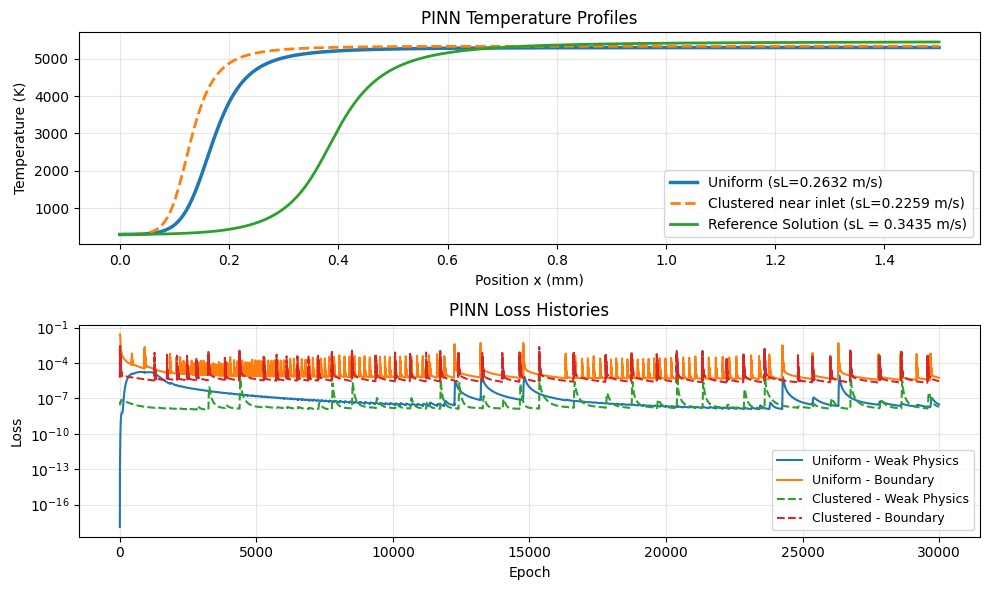

In [125]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
x_reference = np.linspace(0, L, N + 1)

# ==========================================
# LEFT: Temperature profiles
# ==========================================
styles = {
    "Uniform": ("-", 2.5),
    "Clustered near inlet": ("--", 2),
}

for label, profile in pinn_profiles.items():
    linestyle, linewidth = styles.get(label, ("-", 2))

    axes[0].plot(
        profile["x_mm"],
        profile["T"],
        linestyle=linestyle,
        linewidth=linewidth,
        label=f'{label} (sL={profile["sL"]:.4f} m/s)'
    )

axes[0].plot(
    x_reference * 1e3,
    T_all,
    label="Reference Solution (sL = 0.3435 m/s)",
    linewidth=2
)


axes[0].set_xlabel("Position x (mm)")
axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("PINN Temperature Profiles")
axes[0].grid(True, alpha=0.3)
axes[0].legend()


# ==========================================
# RIGHT: All four loss curves
# ==========================================

axes[1].semilogy(
    weak_loss_history_uniform,
    label="Uniform - Weak Physics"
)

axes[1].semilogy(
    bc_loss_history_uniform,
    label="Uniform - Boundary"
)

axes[1].semilogy(
    weak_loss_history_cluster,
    label="Clustered - Weak Physics",
    linestyle="--"
)

axes[1].semilogy(
    bc_loss_history_cluster,
    label="Clustered - Boundary",
    linestyle="--"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title("PINN Loss Histories")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=9)


plt.tight_layout()
plt.show()

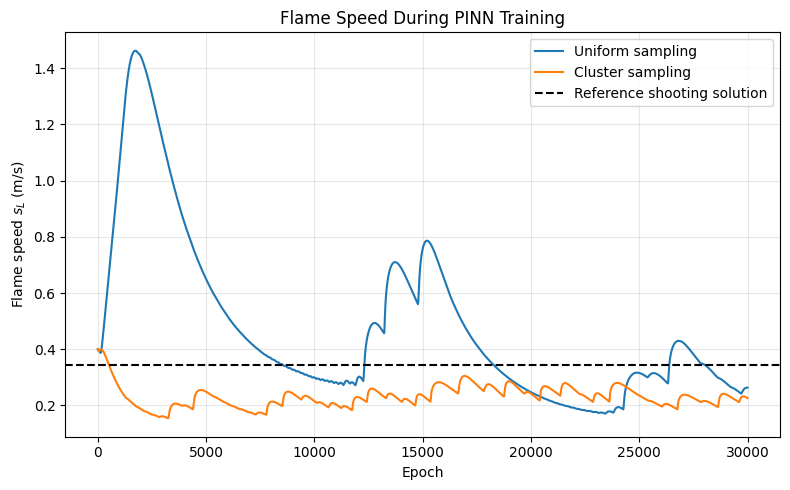

In [126]:
plt.figure(figsize=(8, 5))

plt.plot(sl_uniform, label="Uniform sampling")
plt.plot(sl_cluster, label="Cluster sampling")

plt.axhline(
    y=0.3435,
    linestyle="--",
    label="Reference shooting solution", color = 'black'
)

plt.xlabel("Epoch")
plt.ylabel(r"Flame speed $s_L$ (m/s)")
plt.title("Flame Speed During PINN Training")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()